# NB04 — AEMO pre-dispatch price forecasts

**SOLA4237 Assignment 2 — single-site battery optimisation, Toowoomba (QLD)**

**Purpose.** Turn AEMO's 30-minute pre-dispatch price forecasts (PREDISPATCHPRICE) into the **48-hour, hourly price forecast** that the
rolling-horizon planner sees every hour in 2023 (notebook 7 runs R3 and R4), and measure how accurate it is against the actual 2023 prices.

**Rules**
1. Data: `Predispatch_2023/` — 13 monthly files (Dec 2022 – Dec 2023) from the MMSDM `PREDISP_ALL_DATA` folder (every run kept).
   Keep `REGIONID == 'QLD1'` and `INTERVENTION == 0`. `RRP` $/MWh → $/kWh. `DATETIME` = end of the 30-min period.
2. **No look-ahead:** at plan time t (every hour, hh:00) use the **latest run published at or before t** (`LASTCHANGED ≤ t`).
3. **Hourly:** the hour ending H = mean of the PD periods ending H − 30 min and H (interval-ending labels).
4. **48 h extension:** a run only reaches the end of the next market day (15.5–39 h). For a target hour beyond the run's last hour, use the
   value 24 h or 48 h earlier  from the same information set: the run's own forecast, or — if that time is already past — the
   actual price. This only stretches PD to 48 h; it is not a separate model.

**Inputs:** `Predispatch_2023/*.zip`, `outputs/nb01_clean_2022_2023.csv`.
**Outputs:** `outputs/nb04_pd_forecast_wide_2023.csv` (8,760 plan hours × 48 hourly forecasts + source flags),
`outputs/nb04_pd_runs.csv`, `outputs/nb04_pd_accuracy.csv`, figure fig07c. **Run order:** after NB01.

## Cell 0 — Settings

In [1]:
# Cell 0 - Settings: runs in Google Colab and in local Jupyter
import sys, os
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = '/content/drive/MyDrive/SOLA4237-A2'
else:
    BASE_DIR = os.getcwd()                    # local: the data folder or its 'Notebook' subfolder
    if not os.path.exists(os.path.join(BASE_DIR, 'QLD_spot_price_2023')):
        BASE_DIR = os.path.dirname(BASE_DIR)
sys.path.append(BASE_DIR)
PD_DIR  = os.path.join(BASE_DIR, 'Predispatch_2023')
OUT_DIR = os.path.join(BASE_DIR, 'outputs')
FIG_DIR = os.path.join(OUT_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)
print('BASE_DIR:', BASE_DIR)
print('PD files:', sorted(os.listdir(PD_DIR)))

Mounted at /content/drive
BASE_DIR: /content/drive/MyDrive/SOLA4237-A2
PD files: ['PUBLIC_DVD_PREDISPATCHPRICE_202212010000.zip', 'PUBLIC_DVD_PREDISPATCHPRICE_202301010000.zip', 'PUBLIC_DVD_PREDISPATCHPRICE_202302010000.zip', 'PUBLIC_DVD_PREDISPATCHPRICE_202303010000.zip', 'PUBLIC_DVD_PREDISPATCHPRICE_202304010000.zip', 'PUBLIC_DVD_PREDISPATCHPRICE_202305010000.zip', 'PUBLIC_DVD_PREDISPATCHPRICE_202306010000.zip', 'PUBLIC_DVD_PREDISPATCHPRICE_202307010000.zip', 'PUBLIC_DVD_PREDISPATCHPRICE_202308010000.zip', 'PUBLIC_DVD_PREDISPATCHPRICE_202309010000.zip', 'PUBLIC_DVD_PREDISPATCHPRICE_202310010000.zip', 'PUBLIC_DVD_PREDISPATCHPRICE_202311010000.zip', 'PUBLIC_DVD_PREDISPATCHPRICE_202312010000.zip']


## Cell 1 — Imports and constants

In [2]:
# Cell 1 - imports and constants
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

HORIZON_H = 48                                   # planning horizon (brief)
PLAN_START, PLAN_END = '2023-01-01 00:00', '2023-12-31 23:00'   # one plan per hour in 2023
SPIKE = 0.30                                     # $/kWh (= $300/MWh) threshold for a 'price spike'
COL = {'actual': '#000000', 'h6': '#c44e52', 'h24': '#4c72b0'}
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3, 'axes.spines.top': False, 'axes.spines.right': False})

def save_fig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name), dpi=200, bbox_inches='tight')

## Cell 2 — Read the pre-dispatch files (QLD1, no intervention)
**How:** pandas reads each zipped CSV directly. `skiprows=1` and keep rows where the first column is `D`. Only the needed columns are read (`usecols`) to keep memory low.
**Check:** ~17,500 runs in 2023, one every 30 minutes.

In [3]:
# Cell 2 - read PD zips
USE = ['I', 'PREDISPATCHSEQNO', 'REGIONID', 'INTERVENTION', 'RRP', 'LASTCHANGED', 'DATETIME']
parts = []
for f in sorted(glob.glob(os.path.join(PD_DIR, '*.zip'))):
    d = pd.read_csv(f, skiprows=1, usecols=lambda c: c in USE, low_memory=False)
    d = d[(d['I'] == 'D') & (d['REGIONID'] == 'QLD1')]
    parts.append(d)
    print(os.path.basename(f), len(d))
pdq = pd.concat(parts, ignore_index=True)
n_interv = int((pdq['INTERVENTION'].astype(float) == 1).sum())
pdq = pdq[pdq['INTERVENTION'].astype(float) == 0].copy()
pdq['LASTCHANGED'] = pd.to_datetime(pdq['LASTCHANGED'])
pdq['DATETIME'] = pd.to_datetime(pdq['DATETIME'])
pdq['rrp_aud_kwh'] = pdq['RRP'].astype(float) / 1000.0
pdq['run'] = pdq['PREDISPATCHSEQNO'].astype(str)
pdq = pdq.drop_duplicates(['run', 'DATETIME'], keep='last')
print('QLD1 rows kept:', len(pdq), '| intervention rows dropped:', n_interv)

PUBLIC_DVD_PREDISPATCHPRICE_202212010000.zip 82584
PUBLIC_DVD_PREDISPATCHPRICE_202301010000.zip 82584
PUBLIC_DVD_PREDISPATCHPRICE_202302010000.zip 75075
PUBLIC_DVD_PREDISPATCHPRICE_202303010000.zip 82584
PUBLIC_DVD_PREDISPATCHPRICE_202304010000.zip 79920
PUBLIC_DVD_PREDISPATCHPRICE_202305010000.zip 82584
PUBLIC_DVD_PREDISPATCHPRICE_202306010000.zip 79920
PUBLIC_DVD_PREDISPATCHPRICE_202307010000.zip 82584
PUBLIC_DVD_PREDISPATCHPRICE_202308010000.zip 82584
PUBLIC_DVD_PREDISPATCHPRICE_202309010000.zip 79920
PUBLIC_DVD_PREDISPATCHPRICE_202310010000.zip 82584
PUBLIC_DVD_PREDISPATCHPRICE_202311010000.zip 79920
PUBLIC_DVD_PREDISPATCHPRICE_202312010000.zip 82512
QLD1 rows kept: 1054872 | intervention rows dropped: 483


## Cell 3 — Run table: when each forecast was published and how far it reaches
`published` = latest `LASTCHANGED` in the run (when it became available). Horizon = last forecast period − published time.

In [4]:
# Cell 3 - one row per run
runs = pdq.groupby('run').agg(published=('LASTCHANGED', 'max'), first_period=('DATETIME', 'min'),
                              last_period=('DATETIME', 'max'), n_periods=('DATETIME', 'size')).sort_values('published')
runs['horizon_h'] = (runs['last_period'] - runs['published']).dt.total_seconds() / 3600
gap = runs['published'].diff().dt.total_seconds() / 60
print('runs:', len(runs), '| published from', runs.published.min(), 'to', runs.published.max())
print('gap between runs (min):', gap.value_counts().head(3).to_dict())
print('horizon (h) quantiles:', runs['horizon_h'].quantile([0, .25, .5, .75, 1]).round(1).to_dict())

runs: 19007 | published from 2022-12-01 04:01:34 to 2024-01-01 03:32:06
gap between runs (min): {30.0: 935, 29.983333333333334: 814, 29.933333333333334: 808}
horizon (h) quantiles: {0.0: 16.0, 0.25: 21.7, 0.5: 27.5, 0.75: 33.5, 1.0: 39.5}


## Cell 4 — Hourly forecasts per run, and the actual hourly price
Hour ending H = mean of PD periods ending in (H − 1 h, H]. The actual hourly price is the mean of the 5-min actual prices in the same hour
(from notebook 1; 2022 is included so that history before 1 Jan 2023 is available for the extension rule).

In [5]:
# Cell 4 - hourly PD per run and hourly actual price
pdq['hour_end'] = pdq['DATETIME'].dt.ceil('h')
pd_hourly = pdq.groupby(['run', 'hour_end'])['rrp_aud_kwh'].mean()
print('hourly PD values:', len(pd_hourly))

clean = pd.read_csv(os.path.join(OUT_DIR, 'nb01_clean_2022_2023.csv'), usecols=['datetime', 'spot_aud_kwh'], parse_dates=['datetime'])
actual_h = clean.set_index('datetime')['spot_aud_kwh'].resample('h', label='right', closed='right').mean()
print('actual hourly prices:', actual_h.index.min(), '->', actual_h.index.max())

hourly PD values: 532188
actual hourly prices: 2022-01-01 00:00:00 -> 2024-01-01 00:00:00


## Cell 5 — Build the 48 h forecast for every plan hour (no look-ahead, 48 h extension)
For plan time t: run = latest run with `published ≤ t` (`merge_asof`). Targets: hours ending t + 1 h … t + 48 h.
Source flags: `pd` (direct PD value), `ext_pd` (24/48 h-earlier PD value from the same run), `ext_actual` (24/48 h-earlier actual price, already known at t).

In [6]:
# Cell 5 - plan-hour x horizon grid
plans = pd.DataFrame({'plan_time': pd.date_range(PLAN_START, PLAN_END, freq='h')})
plans = pd.merge_asof(plans, runs.reset_index()[['run', 'published', 'last_period']].sort_values('published'),
                      left_on='plan_time', right_on='published', direction='backward')
assert plans['run'].notna().all(), 'a plan hour has no pre-dispatch run available'
plans['run_last_hour'] = plans['last_period'].dt.floor('h')        # last hour fully or partly covered

grid = plans.loc[plans.index.repeat(HORIZON_H)].reset_index(drop=True)
grid['h'] = np.tile(np.arange(1, HORIZON_H + 1), len(plans))
grid['target'] = grid['plan_time'] + pd.to_timedelta(grid['h'], unit='h')

def lookup_pd(run, when):
    # PD hourly value for (run, hour_end); NaN where the run has no value
    idx = pd.MultiIndex.from_arrays([run, when])
    return pd_hourly.reindex(idx).to_numpy()

grid['price'] = lookup_pd(grid['run'], grid['target'])
grid['source'] = np.where(grid['price'].notna(), 'pd', '')

# extension: step back 24 h, then 48 h, from the same information set
for back in (24, 48):
    miss = grid['price'].isna()
    if not miss.any():
        break
    src_time = grid.loc[miss, 'target'] - pd.Timedelta(hours=back)
    known_actual = src_time <= grid.loc[miss, 'plan_time']           # already happened at plan time -> actual is known
    val_pd = lookup_pd(grid.loc[miss, 'run'], src_time)
    val_act = actual_h.reindex(src_time).to_numpy()
    val = np.where(known_actual, val_act, val_pd)
    grid.loc[miss, 'price'] = val
    grid.loc[miss, 'source'] = np.where(pd.notna(val), np.where(known_actual, 'ext_actual', 'ext_pd'), '')

assert grid['price'].notna().all(), 'some forecast hours are still empty'
print(grid['source'].value_counts(normalize=True).mul(100).round(1).astype(str) + ' %')
print('share of hours taken directly from PD, by horizon block:')
print(grid.assign(block=pd.cut(grid.h, [0, 12, 24, 36, 48])).groupby('block', observed=True)['source'].apply(lambda s: (s == 'pd').mean()).round(2))

source
pd            57.3 %
ext_pd        36.5 %
ext_actual     6.2 %
Name: proportion, dtype: object
share of hours taken directly from PD, by horizon block:
block
(0, 12]     1.00
(12, 24]    0.88
(24, 36]    0.40
(36, 48]    0.02
Name: source, dtype: float64


## Cell 6 — Accuracy against actual 2023 prices (hourly)
**Metrics** MAE and RMSE in $/MWh by horizon block, split by source. Reference: the
**seasonal-naive** forecast (actual price at the same hour the day before) — does pre-dispatch beat it?
**Extremes:** for hours where the actual price was a spike (> $300/MWh) or negative, how often did the forecast (issued 7–24 h ahead) point the same way?

In [7]:
# Cell 6 - accuracy
ev = grid[grid['target'] <= actual_h.index.max()].copy()
ev['actual'] = actual_h.reindex(ev['target']).to_numpy()
ev['naive'] = actual_h.reindex(ev['target'] - pd.Timedelta(hours=24)).to_numpy()
ev['err'] = (ev['price'] - ev['actual']) * 1000            # $/MWh
ev['err_naive'] = (ev['naive'] - ev['actual']) * 1000
ev['block'] = pd.cut(ev['h'], [0, 6, 24, 48], labels=['1-6 h', '7-24 h', '25-48 h'])

def mae_rmse(e):
    return pd.Series({'MAE_$MWh': e.abs().mean(), 'median_abs_$MWh': e.abs().median(), 'bias_$MWh': e.mean(),
                      'RMSE_$MWh': np.sqrt((e ** 2).mean()), 'n': len(e)})

acc = ev.groupby('block', observed=True)['err'].apply(mae_rmse).unstack()
acc_naive = ev.groupby('block', observed=True)['err_naive'].apply(mae_rmse).unstack()
acc_src = ev.groupby('source')['err'].apply(mae_rmse).unstack()
print('Pre-dispatch (incl. extension) by horizon:'); print(acc.round(1))
print('\nSeasonal naive (same hour yesterday) by horizon:'); print(acc_naive.round(1))
print('\nBy source:'); print(acc_src.round(1))

mid = ev[ev['h'].between(7, 24)]
spike = mid[mid['actual'] > SPIKE]
negative = mid[mid['actual'] < 0]
fc_spike = mid[mid['price'] > SPIKE]
normal = mid[(mid['price'].abs() < SPIKE) & (mid['actual'].abs() < SPIKE)]
extremes = pd.Series({
    'actual spike hours (7-24 h pairs)': len(spike),
    'share forecast also > $300/MWh (hit rate)': (spike['price'] > SPIKE).mean(),
    'forecast spike hours (7-24 h pairs)': len(fc_spike),
    'share that really spiked (precision)': (fc_spike['actual'] > SPIKE).mean(),
    'actual negative hours (7-24 h pairs)': len(negative),
    'share forecast also < 0': (negative['price'] < 0).mean(),
    'mean forecast $/MWh (7-24 h)': mid['price'].mean() * 1000,
    'mean actual $/MWh': mid['actual'].mean() * 1000,
    'MAE normal hours: pre-dispatch': normal['err'].abs().mean(),
    'MAE normal hours: seasonal naive': normal['err_naive'].abs().mean()})
print('\nExtremes and bias:'); print(extremes.round(2))

Pre-dispatch (incl. extension) by horizon:
         MAE_$MWh  median_abs_$MWh  bias_$MWh  RMSE_$MWh         n
block                                                             
1-6 h        51.7             14.4       19.3      433.2   52545.0
7-24 h       93.1             19.0       58.5      742.5  157419.0
25-48 h     107.8             25.5       64.6      789.7  209388.0

Seasonal naive (same hour yesterday) by horizon:
         MAE_$MWh  median_abs_$MWh  bias_$MWh  RMSE_$MWh         n
block                                                             
1-6 h        47.6             20.7        0.1      227.5   52545.0
7-24 h       47.6             20.7        0.1      227.6  157419.0
25-48 h      47.7             20.7        0.1      227.9  209388.0

By source:
            MAE_$MWh  median_abs_$MWh  bias_$MWh  RMSE_$MWh         n
source                                                               
ext_actual      35.0             22.7        0.1       74.0   26172.0
ext_pd         

**How to read the test-run result:** pre-dispatch is better than the naive forecast in a *typical* hour (lower median error, and lower MAE
when neither forecast nor actual is extreme), but it forecasts many spikes that never happen (low precision), which gives it a large upward
bias and a worse overall MAE/RMSE beyond a few hours ahead. For the battery this means: it will often hold charge for phantom evening
spikes — a likely source of value loss in R3/R4 (NB07) and a key point for §3.2.

## Cell 7 — Figure: the 2023 week with the highest prices
Actual hourly price vs the forecast made 6 h and 24 h earlier. This explains, better than any metric, what the planner can and cannot see.

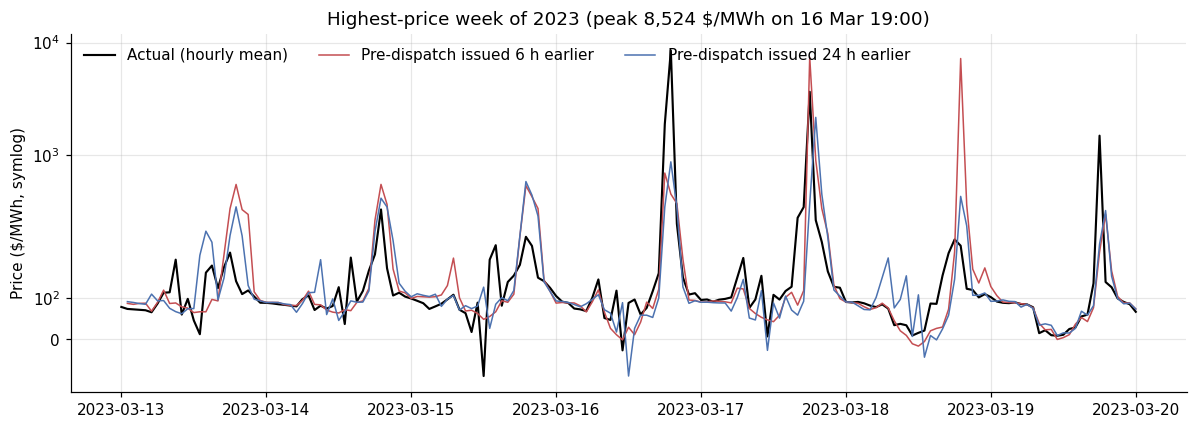

In [8]:
# Cell 7 - spike-week figure
a23 = actual_h[(actual_h.index > '2023-01-01') & (actual_h.index <= '2024-01-01')]
peak_time = a23.idxmax()
start = (peak_time - pd.Timedelta(days=3)).floor('D')
end = start + pd.Timedelta(days=7)
fc = ev[(ev.target > start) & (ev.target <= end)]
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(a23[start:end].index, a23[start:end] * 1000, color=COL['actual'], lw=1.4, label='Actual (hourly mean)')
for hh, c in [(6, 'h6'), (24, 'h24')]:
    s = fc[fc.h == hh].set_index('target')['price'] * 1000
    ax.plot(s.index, s.values, color=COL[c], lw=1, label=f'Pre-dispatch issued {hh} h earlier')
ax.set_yscale('symlog', linthresh=300)
ax.set_ylabel('Price ($/MWh, symlog)')
ax.set_title(f'Highest-price week of 2023 (peak {a23.max()*1000:,.0f} $/MWh on {peak_time:%d %b %H:%M})')
ax.legend(frameon=False, ncol=3); plt.tight_layout(); save_fig(fig, 'fig07c_predispatch_spike_week.png'); plt.show()

## Cell 8 — Save outputs for Notebook 7
- **Wide forecast table**: one row per plan hour (8,760), columns `h01 … h48` = forecast price ($/kWh) for the hour ending plan_time + h,
  and `src01 … src48` = source flag. NB07 reads one row per planning step.
- Run table and accuracy tables for the report and Appendix.

In [9]:
# Cell 8 - save
wide_p = grid.pivot(index='plan_time', columns='h', values='price')
wide_p.columns = [f'h{h:02d}' for h in wide_p.columns]
wide_s = grid.pivot(index='plan_time', columns='h', values='source')
wide_s.columns = [f'src{h:02d}' for h in wide_s.columns]
wide = wide_p.join(wide_s).join(plans.set_index('plan_time')[['run', 'published']])
wide.to_csv(os.path.join(OUT_DIR, 'nb04_pd_forecast_wide_2023.csv'))
runs.to_csv(os.path.join(OUT_DIR, 'nb04_pd_runs.csv'))
pd.concat({'predispatch': acc, 'seasonal_naive': acc_naive}).to_csv(os.path.join(OUT_DIR, 'nb04_pd_accuracy.csv'))
acc_src.to_csv(os.path.join(OUT_DIR, 'nb04_pd_accuracy_by_source.csv'))
extremes.to_frame('value').to_csv(os.path.join(OUT_DIR, 'nb04_pd_extremes.csv'))
print('saved wide table:', wide.shape)

saved wide table: (8760, 98)


## AI-use record (Appendix A)
| Item | Entry |
|---|---|
| Tool & model | Claude Opus 5.5 (Anthropic), claude.ai |
| What AI did | Drafted this notebook from my notes after checking AEMO predispatch file |
| Example prompt | “notebook 3 done now proceed with drafting notebook 4” |
| How I checked it | ran it in Colab; picked one plan hour and checked its 48 values against the raw PD file by hand; confirmed no forecast uses a run published after the plan time |